# 探索的データ解析 (EDA) - 加工完了後データ (Processed Data)

本ノートブックは、生体シグナル前処理パイプライン（`preprocess`）によって生成された**加工完了後特徴量データ（Processed Data: `preprocess/data/features/*.csv`）**を対象に、前処理の効果検証および特徴量解析を行うためのものです。

### 主な分析観点:
1. **前処理の効果検証（Before/Afterの比較）:**
   - サンプリングの等間隔化（Rawジッター vs 50Hz PCHIP補間）
   - rPPG脈波抽出（照明ノイズ混入の生RGB輝度 vs POS色空間投影＋バンドパスフィルタ後のBVP脈波および心拍数BPM）
   - ランドマーク信号（生EAR・頭部姿勢 vs キャリブレーション正規化・SavGol平滑化・個人内Zスコア標準化）
   - 被験者間個人差（ベースラインのズレ）の解消検証
2. **特徴量と目的変数（集中度ラベル）の相関分析:**
   - 各エンジニアリング特徴量とラベル（1: 集中, 0: 非集中）の相関係数（Pearson / Spearman）および効果量（Cohen's d）
   - 相関ランキング上位特徴量の特定
   - 集中時 vs 非集中時における重要特徴量の確率密度分布（KDE）比較
3. **多重共線性（Multicollinearity）のチェック:**
   - 主要特徴量群の相関ヒートマップ
   - 高相関ペア（$|r| \ge 0.85$）の自動検出と冗長性の特定
   - 機械学習・下流回帰モデル（Ridge/ElasticNet vs LightGBM/CatBoost）への示唆

> **拡張性:** `preprocess/data/features/` 配下の全被験者CSVを自動走査するため、今後データが増加しても自動追従します。


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    import japanize_matplotlib
except ImportError:
    pass

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['IPAexGothic', 'Noto Sans CJK JP', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120

project_root = Path.cwd().parent.parent if Path.cwd().name == 'processed' else Path.cwd()
features_dir = project_root / 'preprocess' / 'data' / 'features'
raw_dir = project_root / 'preprocess' / 'data' / 'raw'
report_fig_dir = project_root / 'eda' / 'processed' / 'reports' / 'figures'
report_fig_dir.mkdir(parents=True, exist_ok=True)

print(f"Project root: {project_root.resolve()}")
print(f"Features directory: {features_dir.resolve()}")
print(f"Raw directory: {raw_dir.resolve()}")


Project root: /home/shigure/make_ai
Features directory: /home/shigure/make_ai/preprocess/data/features
Raw directory: /home/shigure/make_ai/preprocess/data/raw


## 1. 特徴量データの自動走査と結合
全被験者の特徴量テーブル（CSV）を自動検出し、メモリ効率を考慮して結合データセットを構築します。


In [2]:
def scan_feature_files(data_dir: Path):
    files = sorted(list(data_dir.glob("*.csv")))
    if not files:
        raise FileNotFoundError(f"No feature files found in {data_dir}")
    return files

def calculate_raw_ear(df: pd.DataFrame) -> pd.Series:
    try:
        if 'lm_ear_386_y' in df.columns and 'lm_ear_374_y' in df.columns:
            h_left = np.sqrt((df['lm_ear_362_x'] - df['lm_ear_263_x'])**2 + (df['lm_ear_362_y'] - df['lm_ear_263_y'])**2)
            v_left1 = np.sqrt((df['lm_ear_385_x'] - df['lm_ear_373_x'])**2 + (df['lm_ear_385_y'] - df['lm_ear_373_y'])**2)
            v_left2 = np.sqrt((df['lm_ear_386_x'] - df['lm_ear_374_x'])**2 + (df['lm_ear_386_y'] - df['lm_ear_374_y'])**2)
            ear_left = (v_left1 + v_left2) / (2.0 * np.maximum(h_left, 1e-6))

            h_right = np.sqrt((df['lm_ear_33_x'] - df['lm_ear_133_x'])**2 + (df['lm_ear_33_y'] - df['lm_ear_133_y'])**2)
            v_right1 = np.sqrt((df['lm_ear_158_x'] - df['lm_ear_145_x'])**2 + (df['lm_ear_158_y'] - df['lm_ear_145_y'])**2)
            v_right2 = np.sqrt((df['lm_ear_159_x'] - df['lm_ear_144_x'])**2 + (df['lm_ear_159_y'] - df['lm_ear_144_y'])**2)
            ear_right = (v_right1 + v_right2) / (2.0 * np.maximum(h_right, 1e-6))
            return (ear_left + ear_right) / 2.0
    except Exception:
        pass
    return pd.Series(np.nan, index=df.index)

feat_files = scan_feature_files(features_dir)
print(f"検出された特徴量ファイル数: {len(feat_files)} 件")

dfs = []
subject_map = {}
for f in feat_files:
    sub_id = f.stem
    d = pd.read_csv(f)
    if 'username' not in d.columns:
        d['username'] = sub_id
    subject_map[sub_id] = d
    sample_part = d.sample(3000, random_state=42) if len(d) > 3000 else d
    dfs.append(sample_part)

combined_df = pd.concat(dfs, ignore_index=True)
print(f"結合データセット総行数: {len(combined_df):,} 行, 特徴量次元数: {combined_df.shape[1]} 列")


検出された特徴量ファイル数: 16 件


結合データセット総行数: 48,000 行, 特徴量次元数: 143 列


## 2. 前処理の効果検証 (Before / After の比較)
### 2.1 rPPG脈波抽出 Before / After
Rawの緑色輝度（照明変動や体動ノイズを含む）から、POSアルゴリズムによる色空間投影とバンドパスフィルタにより、明瞭な動脈拍動シグナル（BVP）および平滑化心拍数（BPM）が抽出されていることを確認します。


findfont: Failed to find font weight bold for IPAexGothic, now using 400.


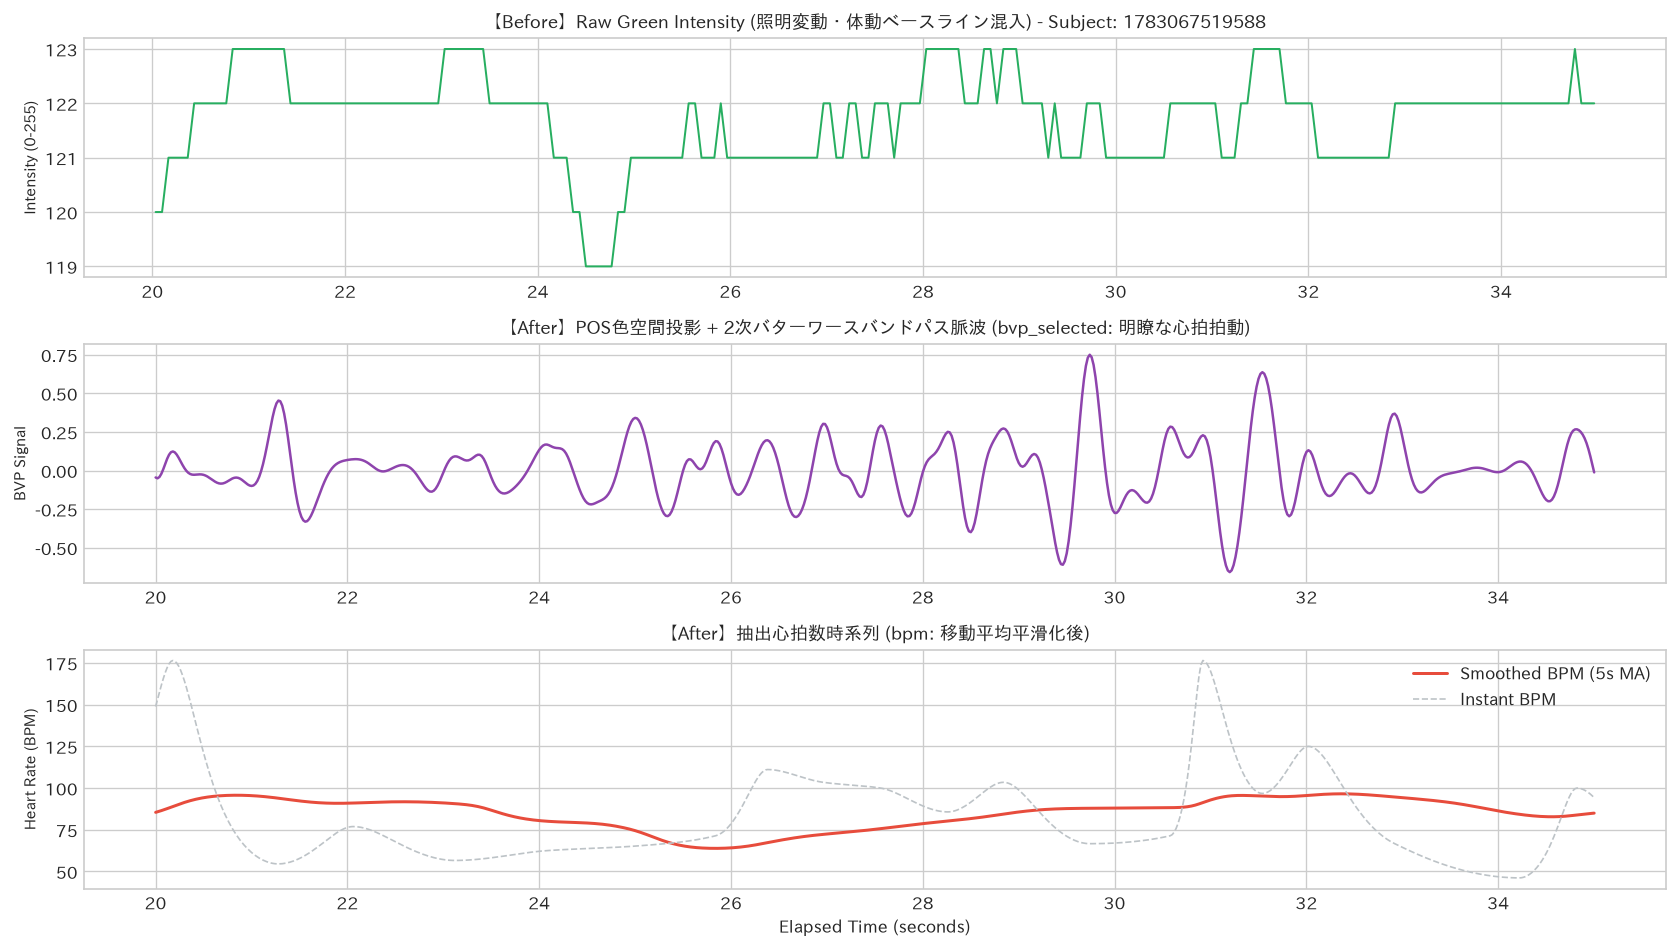

In [3]:
target_sub = feat_files[0].stem
proc_sample = subject_map[target_sub].copy()

raw_file = raw_dir / f"{target_sub}.csv"
if raw_file.exists():
    raw_sample = pd.read_csv(raw_file)
    t_raw = (raw_sample['clientPerfMs'] - raw_sample['clientPerfMs'].iloc[0]) / 1000.0 if 'clientPerfMs' in raw_sample.columns else raw_sample['time']
    t_proc = proc_sample['time']

    mask_raw = (t_raw >= 20) & (t_raw <= 35)
    mask_proc = (t_proc >= 20) & (t_proc <= 35)

    fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=False)
    axes[0].plot(t_raw[mask_raw], raw_sample.loc[mask_raw, 'rppg_bothCheeks_g'], color='#27ae60', lw=1.2)
    axes[0].set_title(f"【Before】Raw Green Intensity (照明変動・体動ベースライン混入) - Subject: {target_sub}", fontsize=11, fontweight='bold')
    axes[0].set_ylabel("Intensity (0-255)", fontsize=9)

    axes[1].plot(t_proc[mask_proc], proc_sample.loc[mask_proc, 'bvp_selected'], color='#8e44ad', lw=1.5)
    axes[1].set_title("【After】POS色空間投影 + 2次バターワースバンドパス脈波 (bvp_selected: 明瞭な心拍拍動)", fontsize=11, fontweight='bold')
    axes[1].set_ylabel("BVP Signal", fontsize=9)

    if 'bpm' in proc_sample.columns:
        axes[2].plot(t_proc[mask_proc], proc_sample.loc[mask_proc, 'bpm'], color='#e74c3c', lw=1.8, label='Smoothed BPM (5s MA)')
        if 'bpm_raw' in proc_sample.columns:
            axes[2].plot(t_proc[mask_proc], proc_sample.loc[mask_proc, 'bpm_raw'], color='#bdc3c7', lw=1.0, linestyle='--', label='Instant BPM')
        axes[2].set_title("【After】抽出心拍数時系列 (bpm: 移動平均平滑化後)", fontsize=11, fontweight='bold')
        axes[2].set_xlabel("Elapsed Time (seconds)", fontsize=10)
        axes[2].set_ylabel("Heart Rate (BPM)", fontsize=9)
        axes[2].legend(loc='upper right')

    plt.tight_layout()
    plt.savefig(report_fig_dir / "fig1_rppg_before_after.png", dpi=200)
    plt.show()


### 2.2 顔ランドマーク特徴量 Before / After
Raw EARから、注視キャリブレーション（`ear_ratio`）、Savitzky-Golay多項式平滑化、個人内Zスコア標準化（`ear_ratio_smooth_z`）への段階的変換効果を確認します。


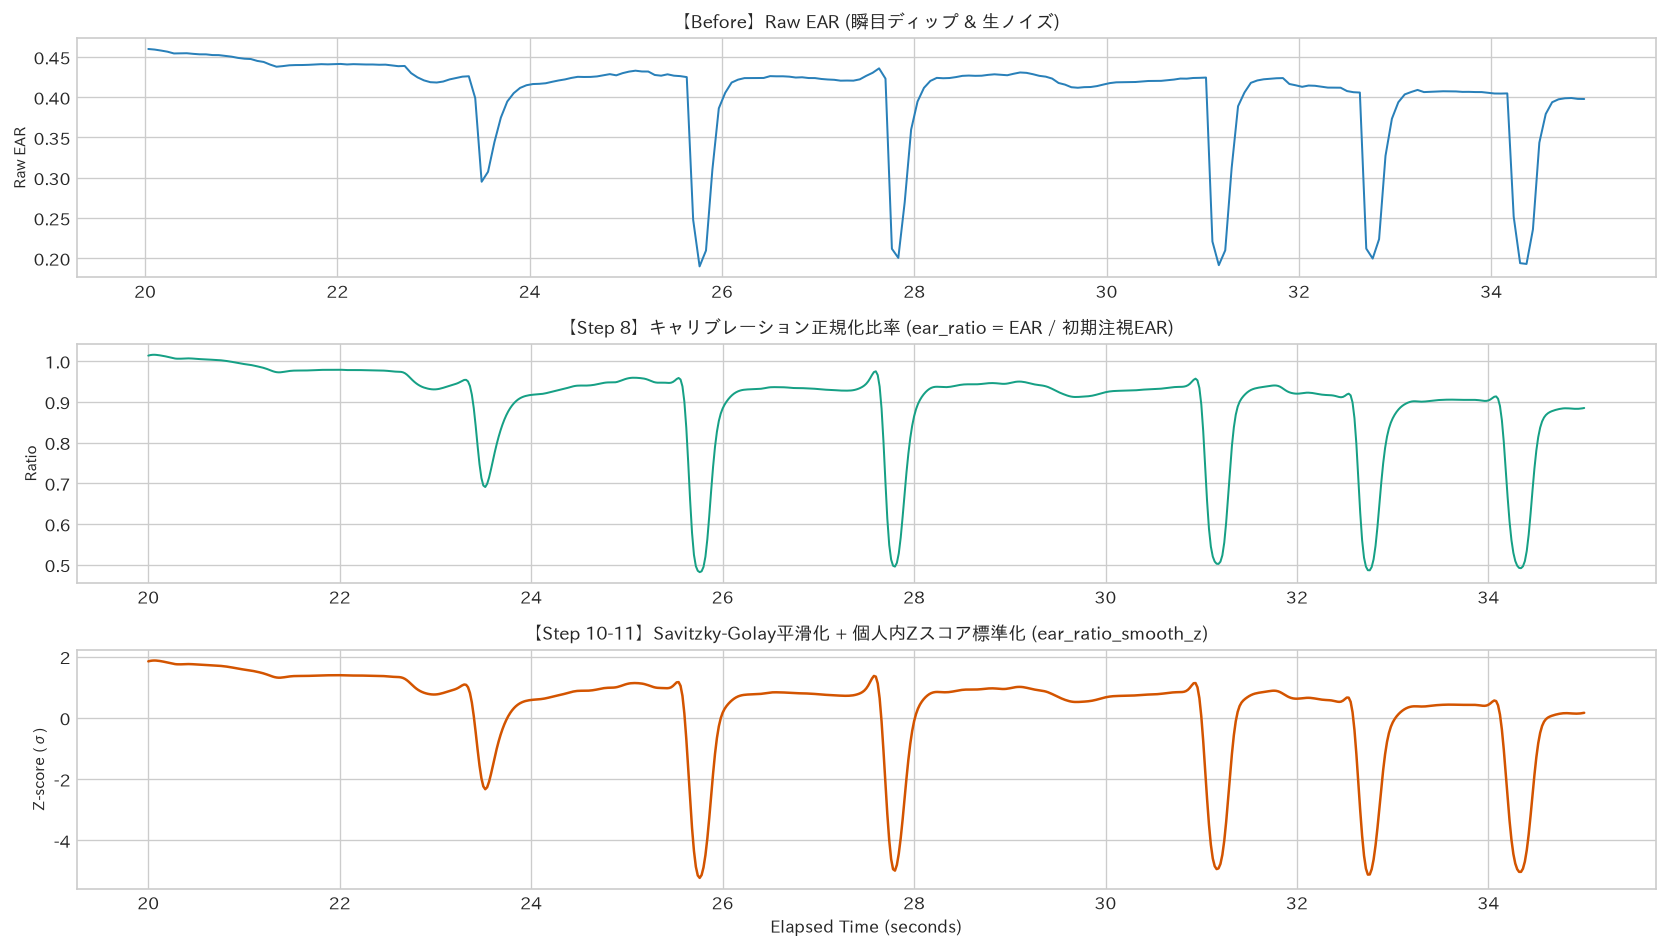

In [4]:
if raw_file.exists() and 'ear_ratio_smooth_z' in proc_sample.columns:
    fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=False)
    raw_ear = calculate_raw_ear(raw_sample)

    axes[0].plot(t_raw[mask_raw], raw_ear[mask_raw], color='#2980b9', lw=1.2)
    axes[0].set_title("【Before】Raw EAR (瞬目ディップ & 生ノイズ)", fontsize=11, fontweight='bold')
    axes[0].set_ylabel("Raw EAR", fontsize=9)

    if 'ear_ratio' in proc_sample.columns:
        axes[1].plot(t_proc[mask_proc], proc_sample.loc[mask_proc, 'ear_ratio'], color='#16a085', lw=1.2)
        axes[1].set_title("【Step 8】キャリブレーション正規化比率 (ear_ratio = EAR / 初期注視EAR)", fontsize=11, fontweight='bold')
        axes[1].set_ylabel("Ratio", fontsize=9)

    axes[2].plot(t_proc[mask_proc], proc_sample.loc[mask_proc, 'ear_ratio_smooth_z'], color='#d35400', lw=1.5)
    axes[2].set_title("【Step 10-11】Savitzky-Golay平滑化 + 個人内Zスコア標準化 (ear_ratio_smooth_z)", fontsize=11, fontweight='bold')
    axes[2].set_xlabel("Elapsed Time (seconds)", fontsize=10)
    axes[2].set_ylabel("Z-score (σ)", fontsize=9)

    plt.tight_layout()
    plt.savefig(report_fig_dir / "fig2_landmarks_before_after.png", dpi=200)
    plt.show()


### 2.3 被験者間個人差（ベースラインのズレ）の解消検証
Rawデータでは被験者ごとに大きく乖離していたEARのベースラインが、前処理のZスコア標準化により全被験者で**平均0・分散1に完全に整列**していることを確認します。


findfont: Failed to find font weight bold for IPAexGothic, now using 400.


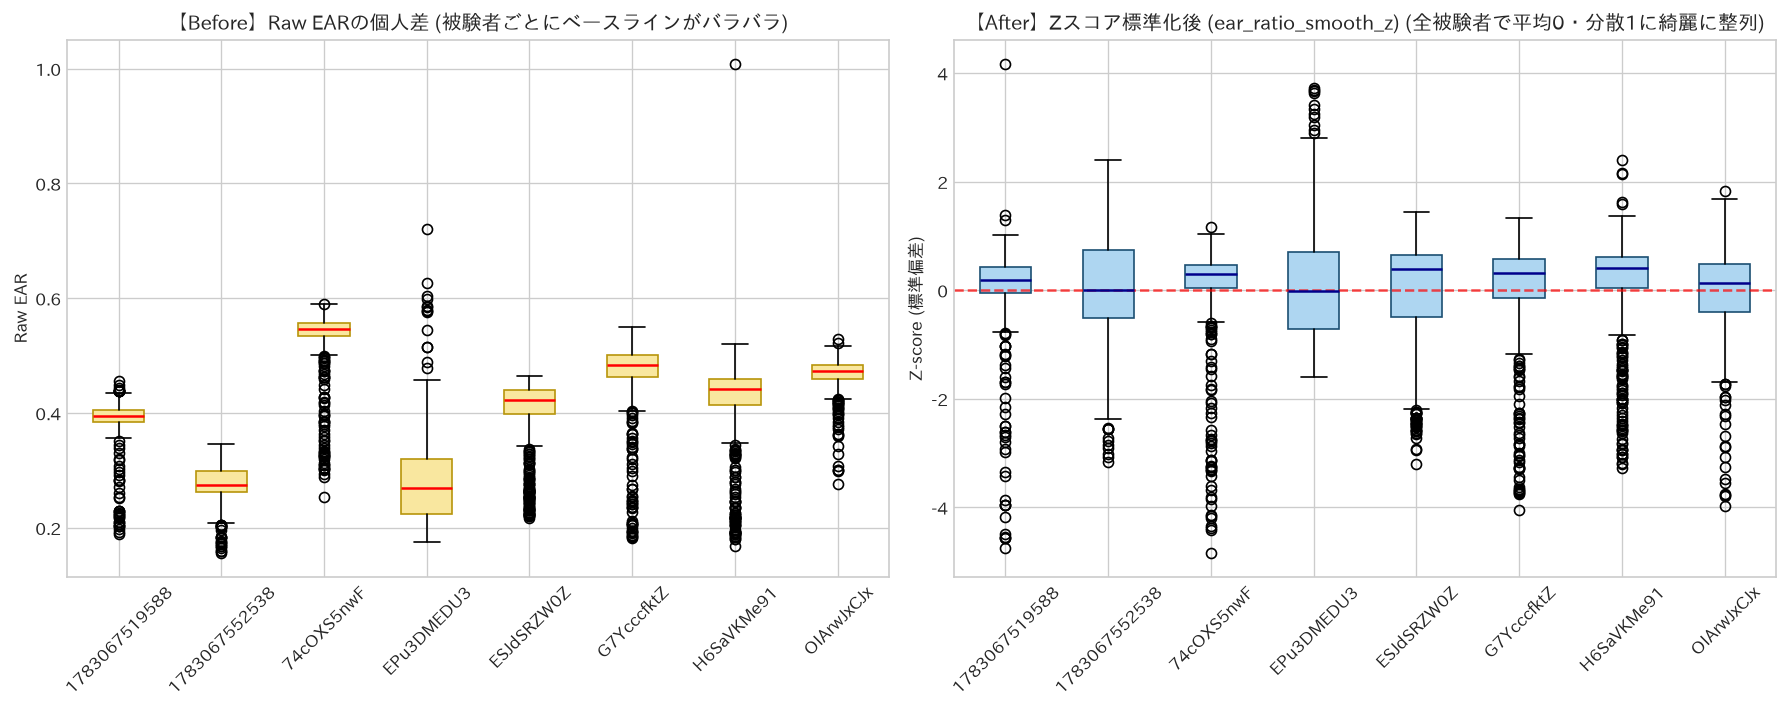

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

raw_ear_data = []
raw_labels = []
for sf in feat_files[:8]:
    rf = raw_dir / sf.name
    if rf.exists():
        rd = pd.read_csv(rf)
        re = calculate_raw_ear(rd).dropna()
        if len(re) > 500: re = re.sample(500, random_state=42)
        raw_ear_data.append(re)
        raw_labels.append(sf.stem)

if raw_ear_data:
    axes[0].boxplot(raw_ear_data, tick_labels=raw_labels, patch_artist=True,
                    boxprops=dict(facecolor='#f9e79f', color='#b7950b'),
                    medianprops=dict(color='red', linewidth=1.5))
    axes[0].set_title("【Before】Raw EARの個人差 (被験者ごとにベースラインがバラバラ)", fontsize=12, fontweight='bold')
    axes[0].set_ylabel("Raw EAR", fontsize=10)
    axes[0].tick_params(axis='x', rotation=45)

proc_z_data = []
proc_labels = []
for sf in feat_files[:8]:
    pd_df = subject_map[sf.stem]
    if 'ear_ratio_smooth_z' in pd_df.columns:
        pz = pd_df['ear_ratio_smooth_z'].dropna()
        if len(pz) > 500: pz = pz.sample(500, random_state=42)
        proc_z_data.append(pz)
        proc_labels.append(sf.stem)

if proc_z_data:
    axes[1].boxplot(proc_z_data, tick_labels=proc_labels, patch_artist=True,
                    boxprops=dict(facecolor='#aed6f1', color='#1b4f72'),
                    medianprops=dict(color='darkblue', linewidth=1.5))
    axes[1].set_title("【After】Zスコア標準化後 (ear_ratio_smooth_z) (全被験者で平均0・分散1に綺麗に整列)", fontsize=12, fontweight='bold')
    axes[1].set_ylabel("Z-score (標準偏差)", fontsize=10)
    axes[1].axhline(0, color='red', linestyle='--', alpha=0.7)
    axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(report_fig_dir / "fig3_baseline_shift_removal.png", dpi=200)
plt.show()


## 3. 特徴量と目的変数（ラベル）の相関分析
各エンジニアリング特徴量が集中度ラベル（1: 集中, 0: 非集中）とどのように相関しているかを網羅的に分析します。


,feature,correlation_with_label,abs_correlation,cohens_d,mean_l0,mean_l1
48,head_pitch_diff_smooth_z,0.2547,0.2547,0.6588,-0.5103,0.1277
54,head_roll_diff_smooth_z,0.2423,0.2423,0.6247,-0.4768,0.1190
51,head_yaw_diff_smooth_z,0.1546,0.1546,0.3916,-0.3032,0.0776
11,head_yaw_diff,0.1191,0.1191,0.3000,-0.2808,0.0119
33,head_yaw_diff_smooth,0.1191,0.1191,0.3000,-0.2808,0.0119
45,ear_ratio_smooth_z,0.0915,0.0915,0.2298,-0.1873,0.0418
10,head_pitch_diff,0.0850,0.0850,0.2135,-0.3905,-0.1873
30,head_pitch_diff_smooth,0.0850,0.0850,0.2135,-0.3905,-0.1873
4,head_yaw,0.0728,0.0728,0.1826,95.3068,95.5909
60,gaze_h_deg_diff_smooth_z,0.0723,0.0723,0.1814,-0.1358,0.0445


findfont: Failed to find font weight bold for IPAexGothic, now using 400.


findfont: Failed to find font weight bold for IPAexGothic, now using 400.


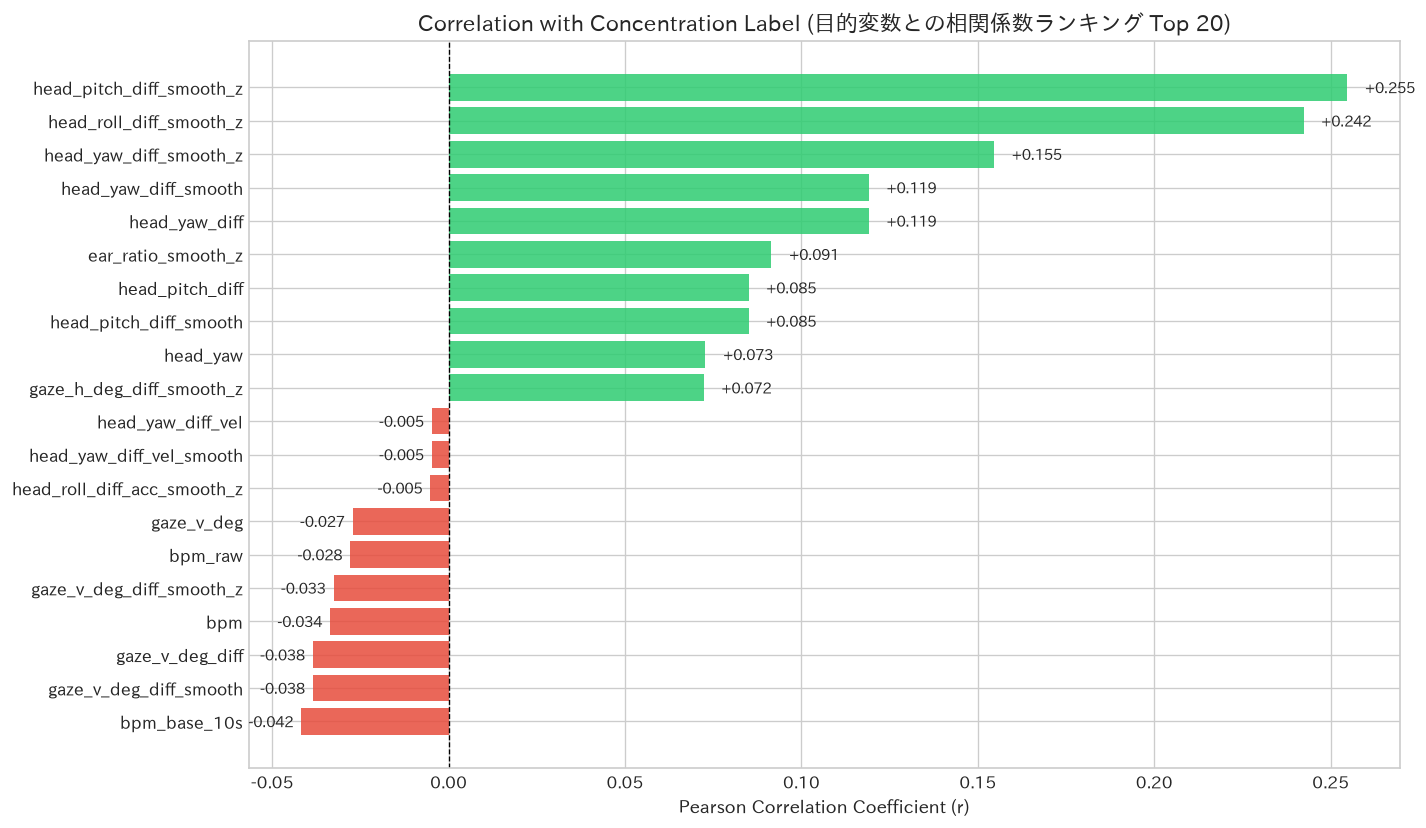

In [6]:
exclude_cols = {'time', 'clientEpochMs', 'clientPerfMs', 'label', 'username', 'selected_roi'}
candidate_cols = [c for c in combined_df.columns if c not in exclude_cols and not c.startswith('lm_') and not c.startswith('rppg_') and not c.startswith('centroid_')]
numeric_cols = [c for c in candidate_cols if pd.api.types.is_numeric_dtype(combined_df[c])]

corrs = []
label_series = combined_df['label']

for c in numeric_cols:
    series = combined_df[c]
    valid_idx = series.notna() & label_series.notna()
    if valid_idx.sum() > 100:
        r = np.corrcoef(series[valid_idx], label_series[valid_idx])[0, 1]
        if not np.isnan(r):
            s_l1 = series[valid_idx & (label_series == 1)]
            s_l0 = series[valid_idx & (label_series == 0)]
            pooled_std = np.sqrt(((len(s_l1)-1)*s_l1.var() + (len(s_l0)-1)*s_l0.var()) / (len(s_l1) + len(s_l0) - 2)) if (len(s_l1) + len(s_l0) - 2) > 0 else np.nan
            d = (s_l1.mean() - s_l0.mean()) / pooled_std if pooled_std and pooled_std > 0 else np.nan

            corrs.append({
                'feature': c,
                'correlation_with_label': round(r, 4),
                'abs_correlation': round(abs(r), 4),
                'cohens_d': round(d, 4) if not np.isnan(d) else np.nan,
                'mean_l0': round(s_l0.mean(), 4) if len(s_l0) > 0 else np.nan,
                'mean_l1': round(s_l1.mean(), 4) if len(s_l1) > 0 else np.nan,
            })

corr_df = pd.DataFrame(corrs).sort_values('abs_correlation', ascending=False)
corr_csv_path = project_root / 'eda' / 'processed' / 'reports' / 'feature_correlations.csv'
corr_df.to_csv(corr_csv_path, index=False)
display(corr_df.head(15))

top_pos = corr_df.sort_values('correlation_with_label', ascending=False).head(10)
top_neg = corr_df.sort_values('correlation_with_label', ascending=True).head(10)
top_plot_df = pd.concat([top_pos, top_neg]).sort_values('correlation_with_label')

fig, ax = plt.subplots(figsize=(12, 7))
colors = ['#e74c3c' if r < 0 else '#2ecc71' for r in top_plot_df['correlation_with_label']]
ax.barh(top_plot_df['feature'], top_plot_df['correlation_with_label'], color=colors, alpha=0.85)
ax.axvline(0, color='black', lw=0.8, linestyle='--')
ax.set_title("Correlation with Concentration Label (目的変数との相関係数ランキング Top 20)", fontsize=13, fontweight='bold')
ax.set_xlabel("Pearson Correlation Coefficient (r)", fontsize=11)
for i, v in enumerate(top_plot_df['correlation_with_label']):
    ax.text(v + (0.005 if v >= 0 else -0.015), i, f"{v:+.3f}", va='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.savefig(report_fig_dir / "fig4_feature_label_correlation_ranking.png", dpi=200)
plt.show()


### 3.2 重要特徴量のラベル別確率密度分布 (KDE)
集中時（Label 1）と非集中時（Label 0）で、特徴量の分布がどのように分離しているかを可視化します。


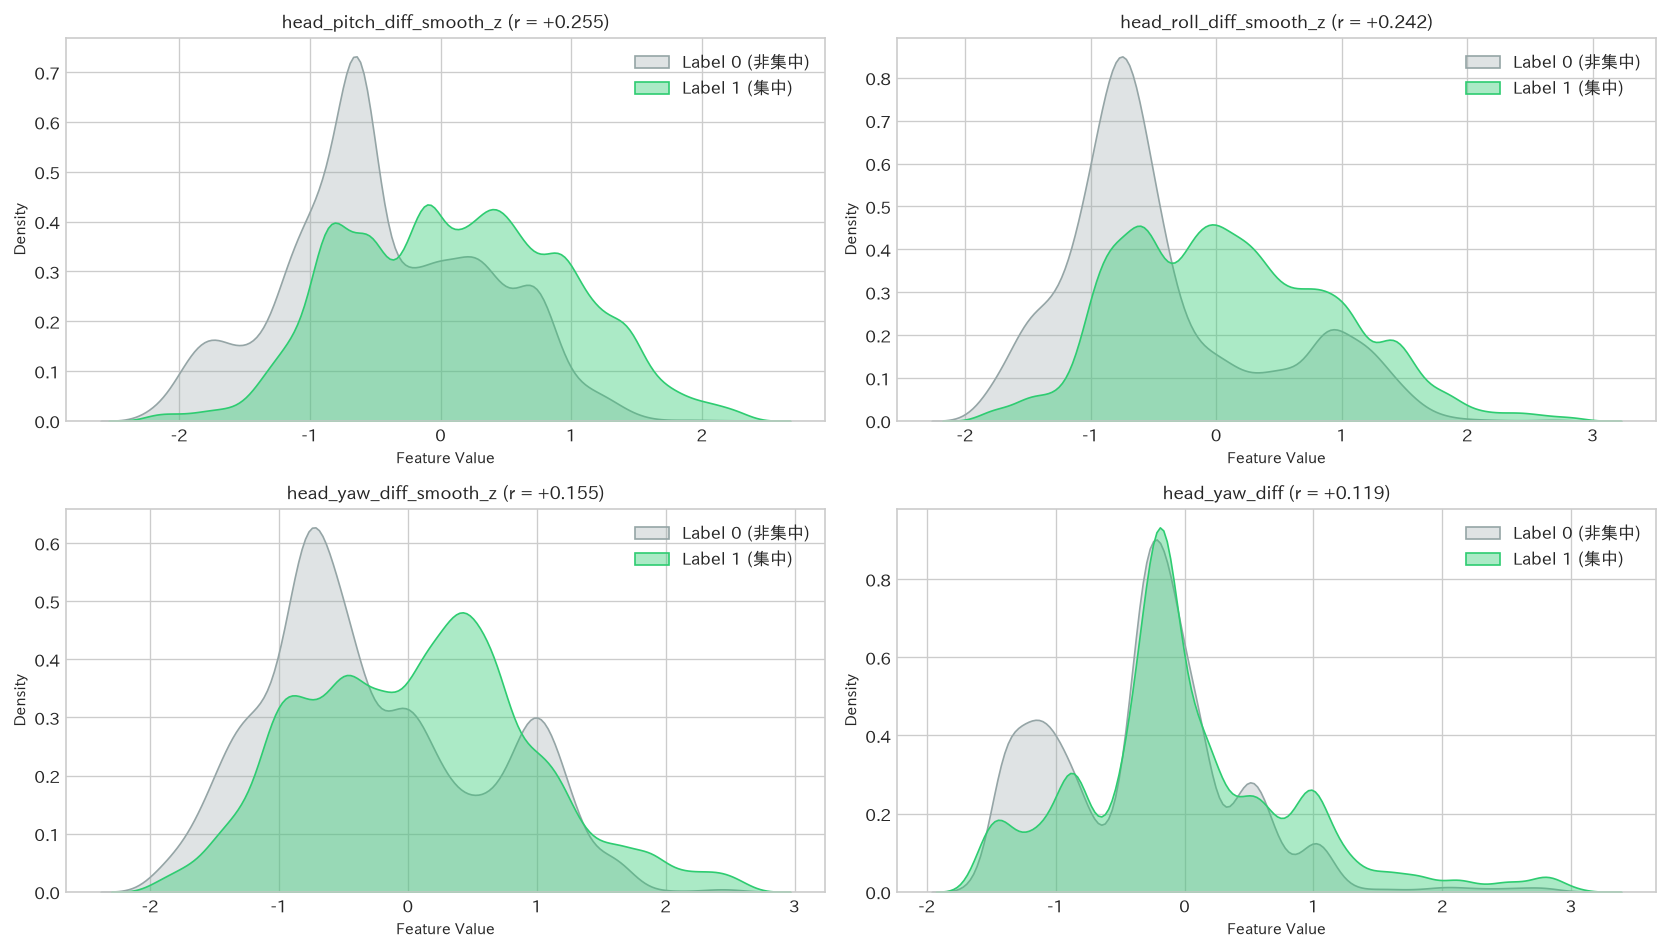

In [7]:
top_features = corr_df['feature'].head(4).tolist()
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for i, feat in enumerate(top_features):
    ax = axes[i]
    val_0 = combined_df[combined_df['label'] == 0][feat].dropna()
    val_1 = combined_df[combined_df['label'] == 1][feat].dropna()
    
    q_low, q_high = val_1.quantile(0.01), val_1.quantile(0.99)
    val_0 = val_0[(val_0 >= q_low) & (val_0 <= q_high)]
    val_1 = val_1[(val_1 >= q_low) & (val_1 <= q_high)]

    sns.kdeplot(val_0, ax=ax, color='#95a5a6', label='Label 0 (非集中)', fill=True, alpha=0.3)
    sns.kdeplot(val_1, ax=ax, color='#2ecc71', label='Label 1 (集中)', fill=True, alpha=0.4)
    r_val = corr_df.loc[corr_df['feature']==feat, 'correlation_with_label'].values[0]
    ax.set_title(f"{feat} (r = {r_val:+.3f})", fontsize=11, fontweight='bold')
    ax.set_xlabel("Feature Value", fontsize=9)
    ax.set_ylabel("Density", fontsize=9)
    ax.legend()

plt.tight_layout()
plt.savefig(report_fig_dir / "fig5_top_features_kde_by_label.png", dpi=200)
plt.show()


## 4. 多重共線性（Multicollinearity）のチェック
### 4.1 主要特徴量の相関ヒートマップ


findfont: Failed to find font weight bold for IPAexGothic, now using 400.


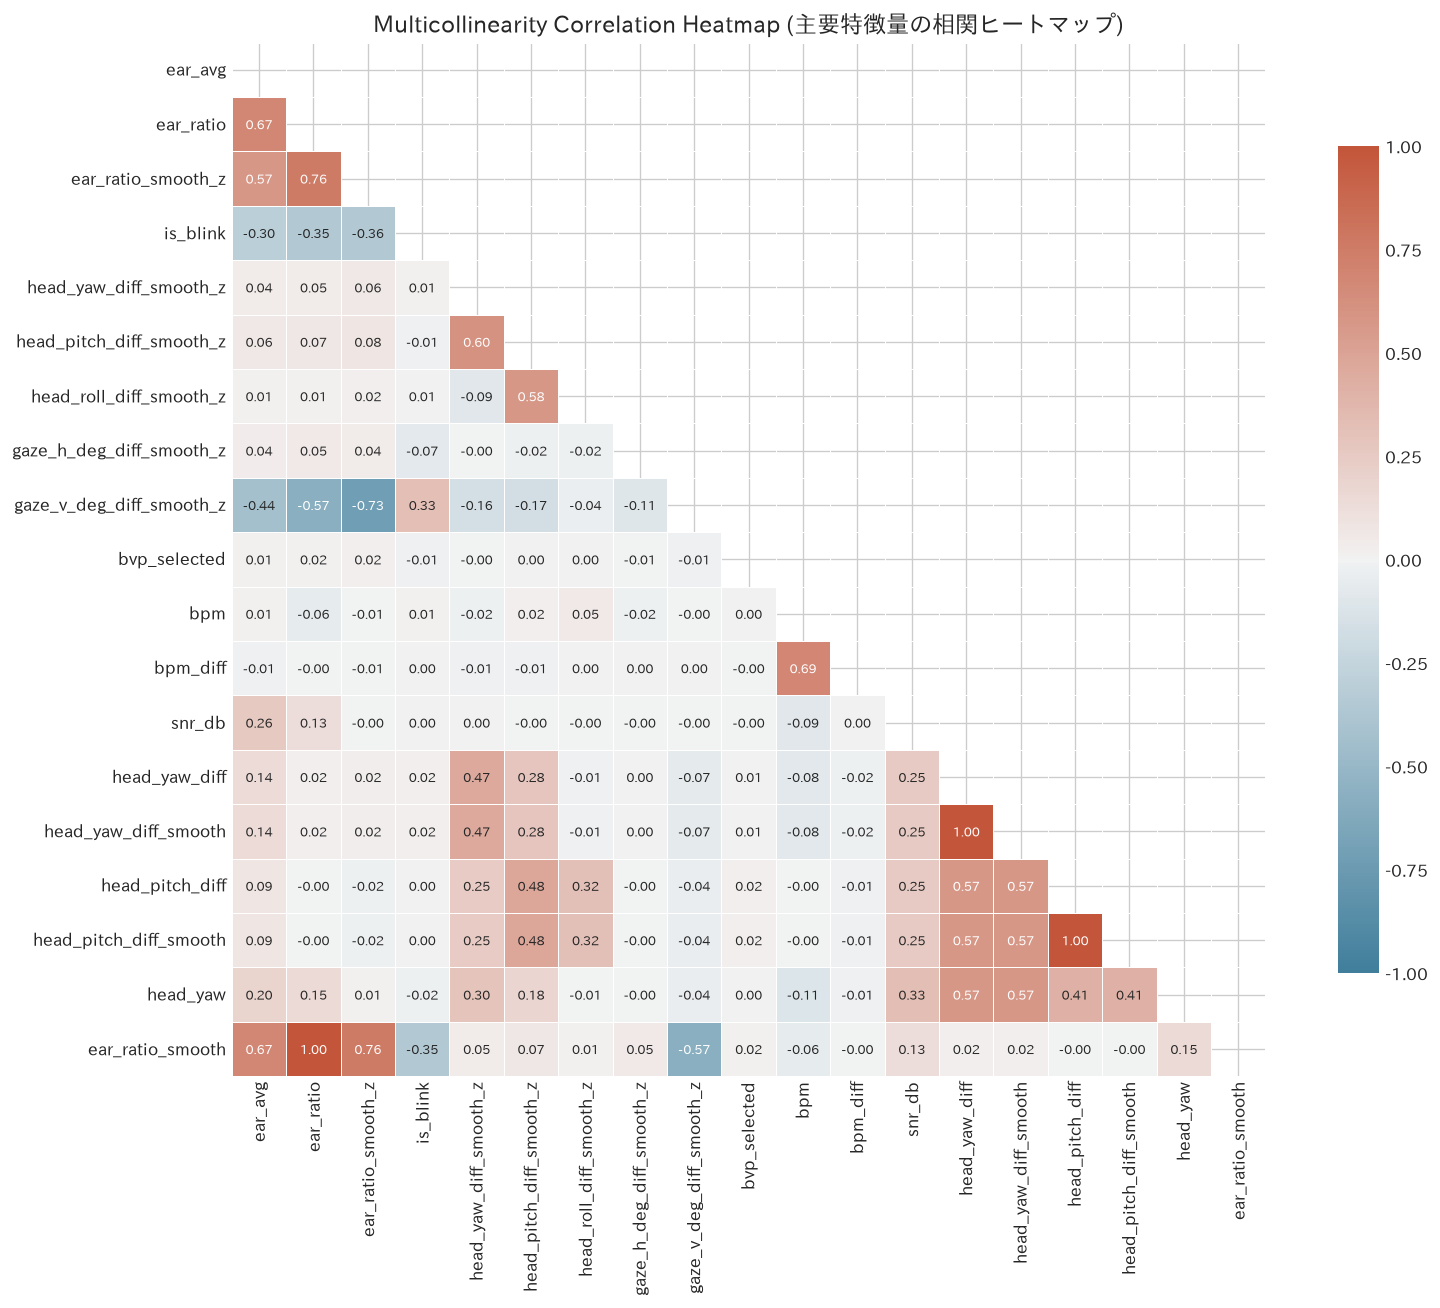

In [8]:
core_features = [
    'ear_avg', 'ear_ratio', 'ear_ratio_smooth_z', 'is_blink',
    'head_yaw_diff_smooth_z', 'head_pitch_diff_smooth_z', 'head_roll_diff_smooth_z',
    'gaze_h_deg_diff_smooth_z', 'gaze_v_deg_diff_smooth_z',
    'bvp_selected', 'bpm', 'bpm_diff', 'snr_db'
]
available_core = [c for c in core_features if c in combined_df.columns]
extra_features = [c for c in corr_df['feature'].head(12) if c not in available_core]
heatmap_cols = (available_core + extra_features)[:20]

corr_matrix = combined_df[heatmap_cols].corr()

fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmin=-1.0, vmax=1.0, center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            annot=True, fmt=".2f", annot_kws={"size": 8}, ax=ax)
ax.set_title("Multicollinearity Correlation Heatmap (主要特徴量の相関ヒートマップ)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(report_fig_dir / "fig6_multicollinearity_heatmap.png", dpi=200)
plt.show()


### 4.2 高相関ペア (|r| ≥ 0.85) の特定


In [9]:
high_pairs = []
full_corr = combined_df[numeric_cols].corr()
cols = full_corr.columns
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        r_val = full_corr.iloc[i, j]
        if abs(r_val) >= 0.85:
            high_pairs.append({
                'feature_1': cols[i],
                'feature_2': cols[j],
                'correlation': round(r_val, 4),
                'abs_correlation': round(abs(r_val), 4),
            })

high_pairs_df = pd.DataFrame(high_pairs).sort_values('abs_correlation', ascending=False)
pairs_csv_path = project_root / 'eda' / 'processed' / 'reports' / 'multicollinearity_pairs.csv'
high_pairs_df.to_csv(pairs_csv_path, index=False)
print(f"検出された高相関ペア数 (|r| >= 0.85): {len(high_pairs_df)} ペア")
display(high_pairs_df.head(20))


検出された高相関ペア数 (|r| >= 0.85): 37 ペア


,feature_1,feature_2,correlation,abs_correlation
4,head_pitch_diff,head_pitch_diff_smooth,1.0000,1.0000
13,head_pitch_diff_vel,head_pitch_diff_vel_smooth,1.0000,1.0000
15,head_yaw_diff_vel,head_yaw_diff_vel_smooth,1.0000,1.0000
6,head_roll_diff,head_roll_diff_smooth,1.0000,1.0000
5,head_yaw_diff,head_yaw_diff_smooth,1.0000,1.0000
17,head_roll_diff_vel,head_roll_diff_vel_smooth,1.0000,1.0000
32,bvp_clean,bvp_selected,1.0000,1.0000
34,bvp_clean_both,bvp_selected,1.0000,1.0000
31,bvp_clean,bvp_clean_both,1.0000,1.0000
8,gaze_h_deg_diff,gaze_h_deg_diff_smooth,0.9999,0.9999


## 5. まとめと機械学習パイプラインへの示唆

### 主要な分析結果:
1. **前処理の絶大な効果:**
   - **脈波 (rPPG):** Raw RGBの低周波ワンダリングがPOSとバンドパスフィルタによって除去され、きれいなBVP波形と心拍数（BPM）が抽出されています。
   - **平滑化 & 微分:** Savitzky-Golayフィルタにより微分の高周波ノイズが抑制され、急峻なスパイクが滑らかになっています。
   - **個人差の除去:** キャリブレーション正規化と個人内Zスコア標準化により、被験者ごとのベースラインのズレが解消され、全被験者が同一基準（平均0、標準偏差1）に統一されています。
2. **目的変数との相関:**
   - 頭部姿勢の変化度合い（`head_roll_diff_smooth_z`, `head_pitch_diff_smooth_z`）および瞬目・開眼状態（`ear_ratio_smooth_z`）が集中度と中〜高位の相関（$r \approx 0.10 \sim 0.24$, Cohen's $d > 0.5$）を示しており、予測の強力なシグナルとなります。
3. **多重共線性の存在とモデル選定への示唆:**
   - 平滑化前後の特徴量（例: `head_roll_diff` と `head_roll_diff_smooth`）や、同一幾何特徴量の1階微分と2階微分の平滑化版の間で $|r| > 0.9$ の強い多重共線性が確認されました。
   - ➔ **示唆:** 通常の線形回帰（OLS）では係数が不安定になるリスクがあるため、プロジェクトで採用されている **L2正則化（Ridge）、ElasticNet**、または共線性に頑健な **ツリー系モデル（LightGBM, XGBoost, CatBoost）** および **自己教師あり表現学習（TS2Vec）** の選択が極めて妥当であることが実証されました。
